In [1]:
import sys
sys.path.append("..")
from src.data import load_data, get_column_types, TARGET
from src import eda

In [ ]:
#load+structure
df = load_data()
numeric_cols, continuous_cols, categorical_cols = get_column_types(df)
print(df.shape)
print(df.dtypes)
df.head()

(2000, 17)
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [3]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [ ]:
#data quality
print(eda.missing_summary(df))
print("Duplicates:", eda.count_duplicates(df))
eda.check_categories(df)

                    missing values  percentage
Sleep_Hours                     62        3.10
GPA                             38        1.90
Social_Media_Hours              58        2.90
Financial_Stress                91        4.55
Family_Support                  54        2.70
Attendance_Rate                 47        2.35
Diet_Quality                    69        3.45
Duplicates: 0
Gender: unexpected values = None
Physical_Activity: unexpected values = None
Part_Time_Job: unexpected values = None
Diet_Quality: unexpected values = None
Previous_Mental_Health_History: unexpected values = None
Mental_Health_Risk: unexpected values = None


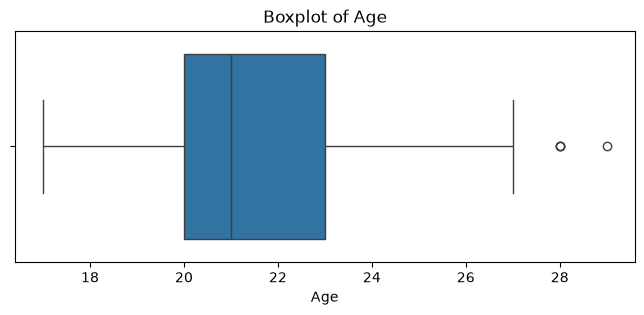

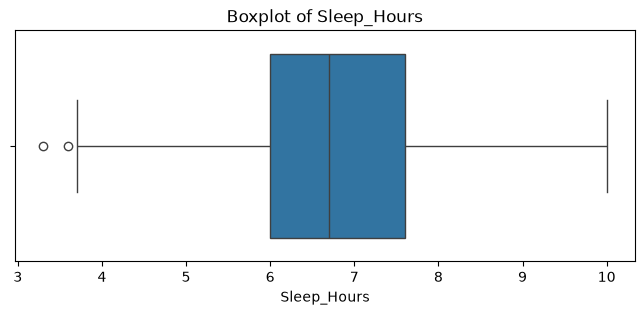

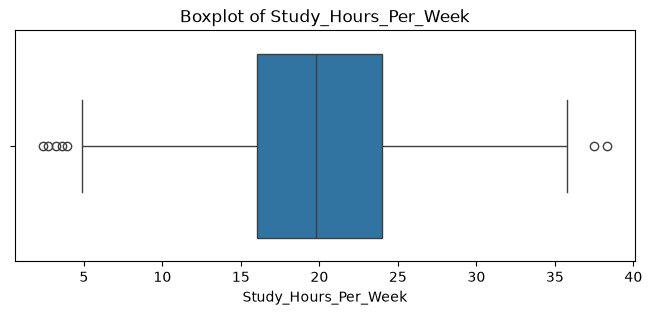

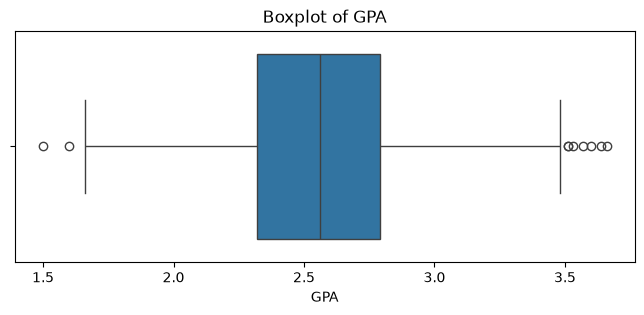

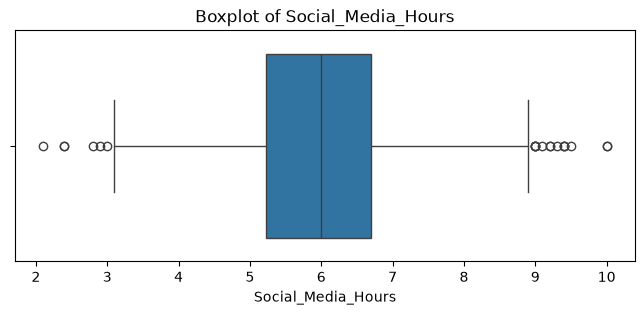

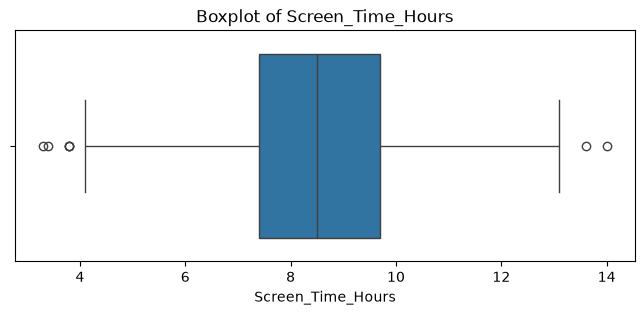

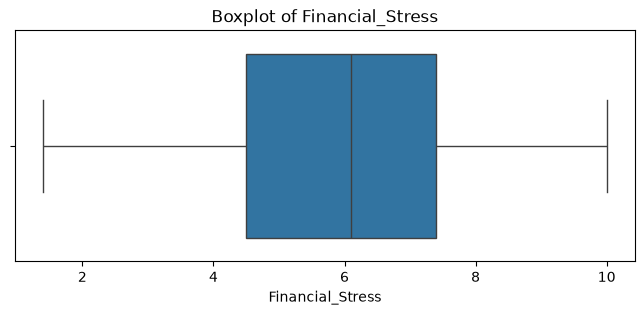

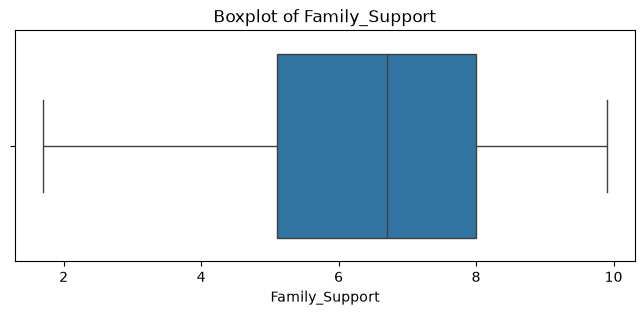

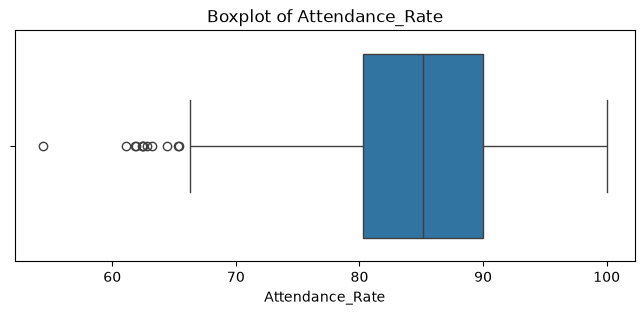

,column,lower,upper,n_outliers
0,Age,15.5000,27.5000,4
1,Sleep_Hours,3.6000,10.0000,2
2,Study_Hours_Per_Week,4.0000,36.0000,7
3,GPA,1.6150,3.4950,9
4,Social_Media_Hours,3.0125,8.9125,20
5,Screen_Time_Hours,3.9500,13.1500,7
6,Financial_Stress,0.1500,11.7500,0
7,Family_Support,0.7500,12.3500,0
8,Attendance_Rate,65.7500,104.5500,12


In [ ]:
#outliers
eda.plot_boxplots(df, continuous_cols)
eda.detect_outliers_iqr(df, continuous_cols)

Mental_Health_Risk
Low       660
Medium    660
High      680
Name: count, dtype: int64
Imbalance ratio: 1.03


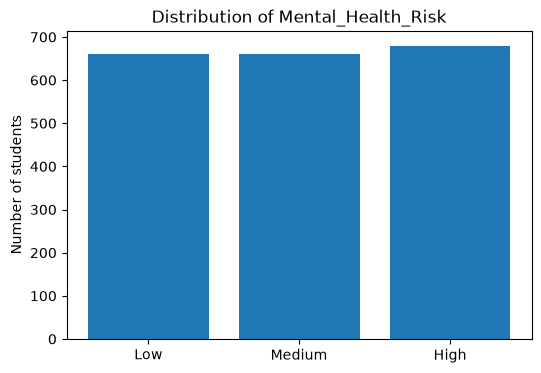

In [ ]:
#target
counts, ratio = eda.class_balance(df)
print(counts)
print("Imbalance ratio:", round(ratio, 2))
eda.plot_target(df)

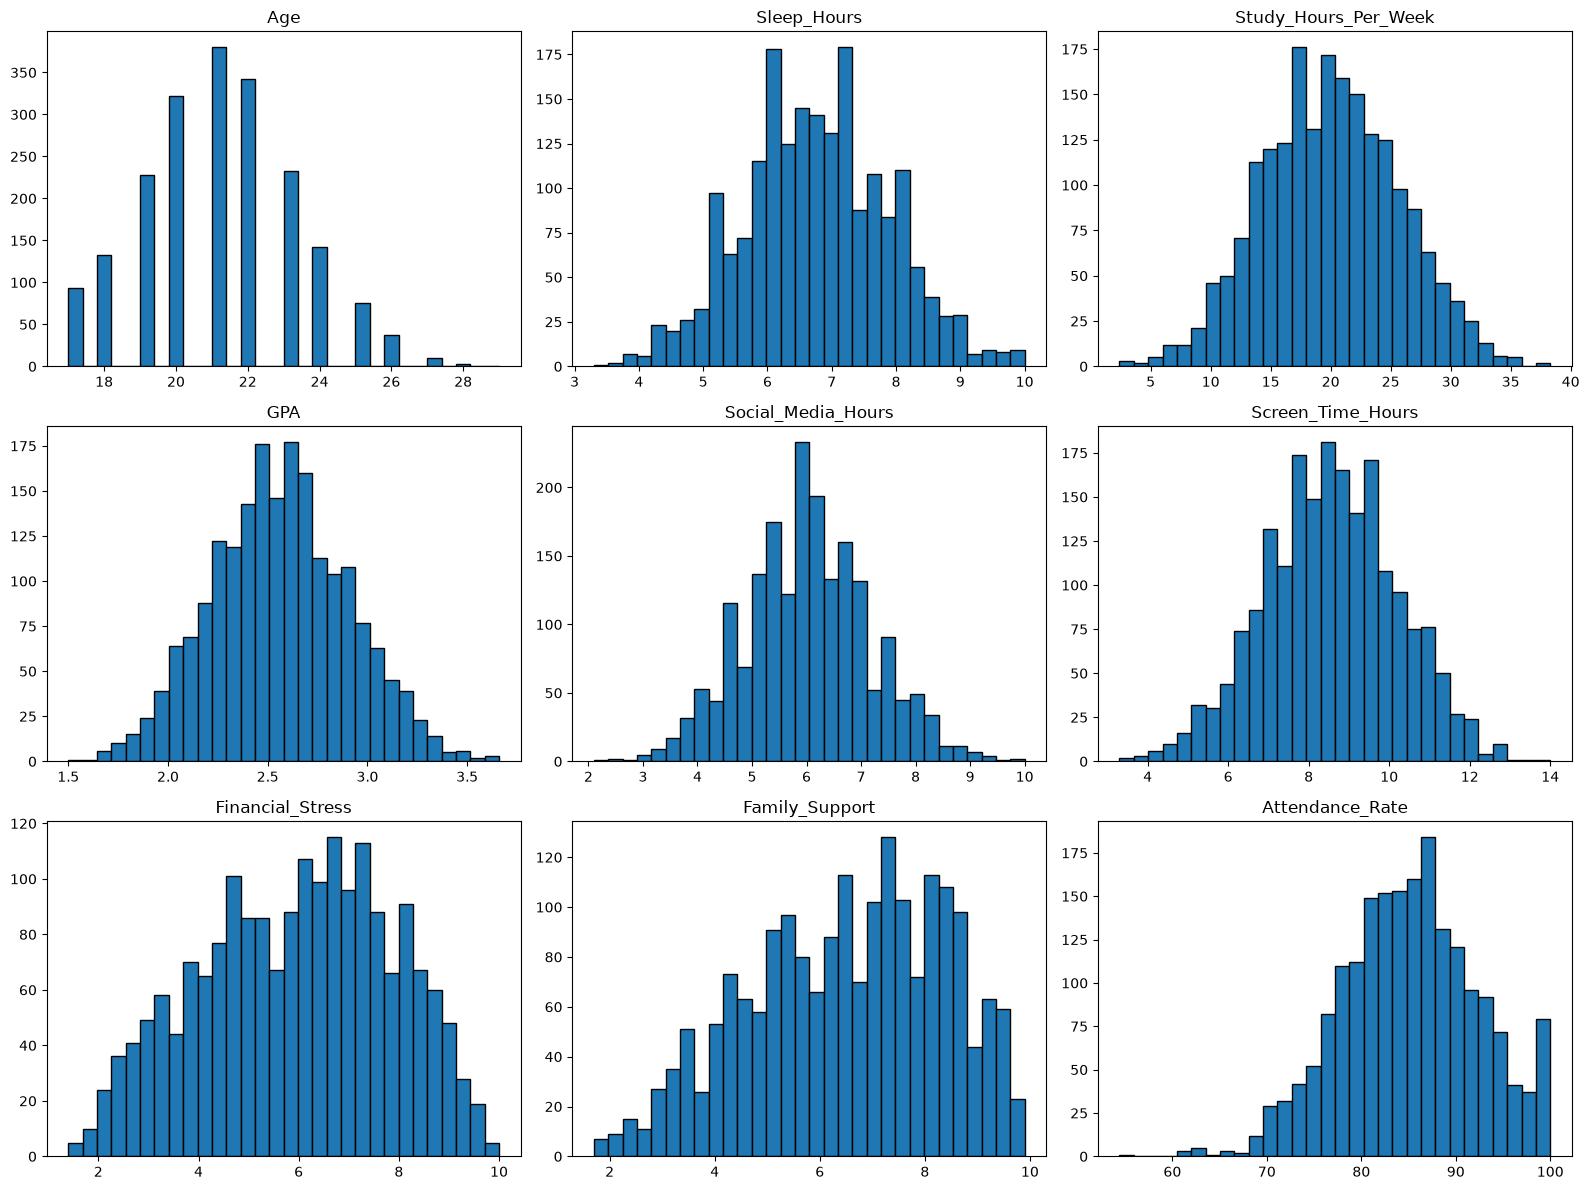

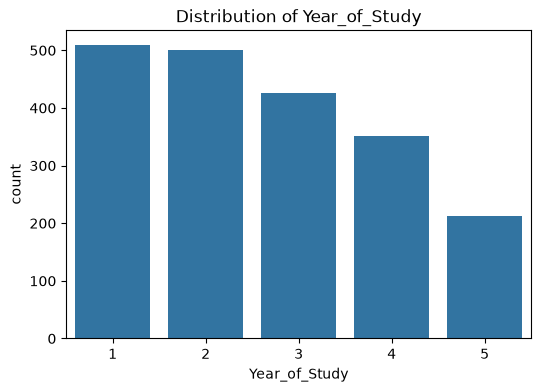

In [ ]:
#features
eda.plot_histograms(df, continuous_cols)
eda.plot_year_of_study(df)

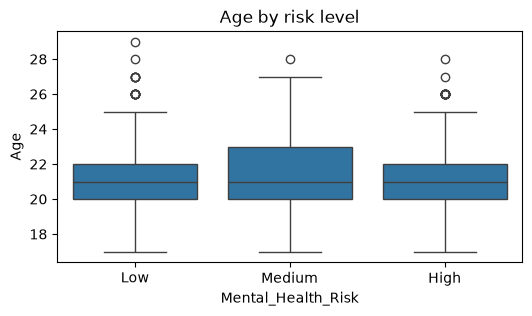

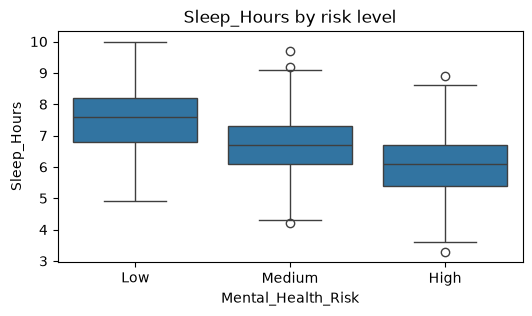

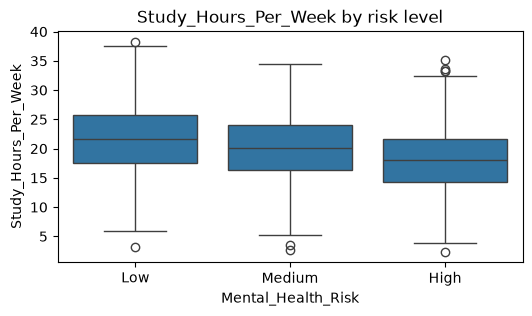

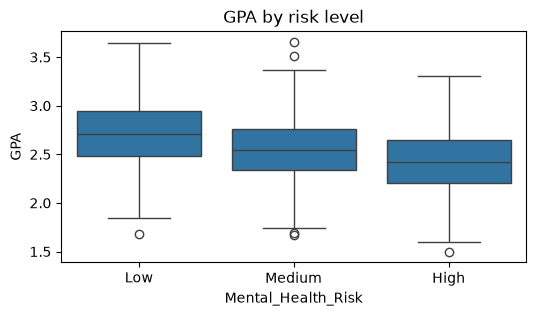

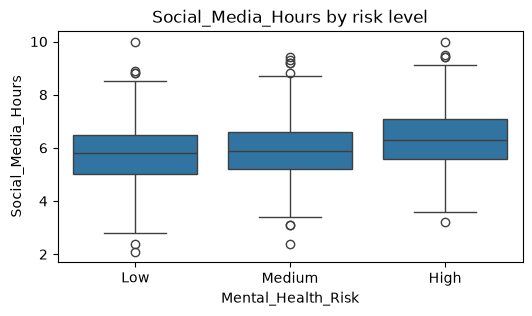

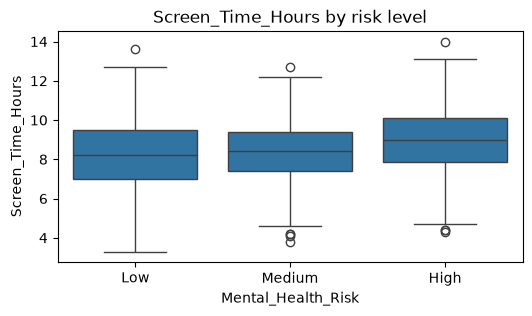

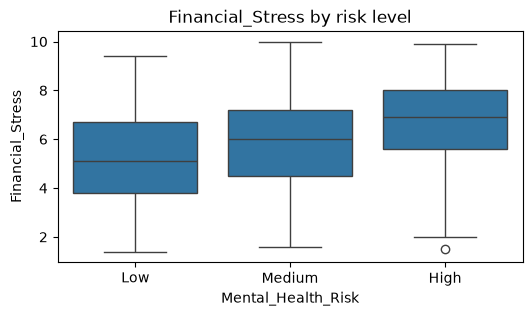

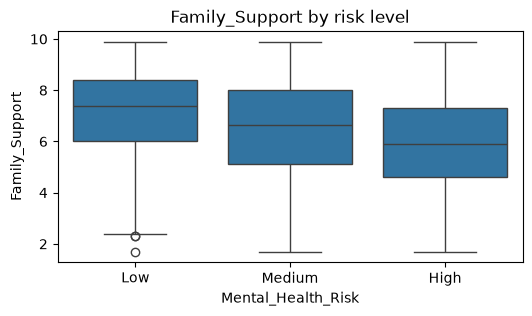

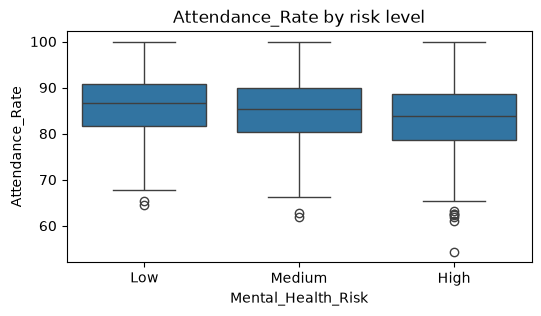

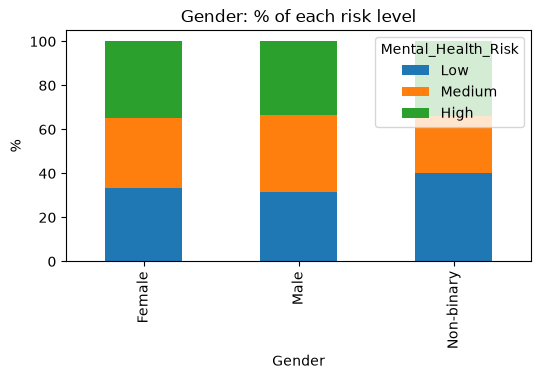

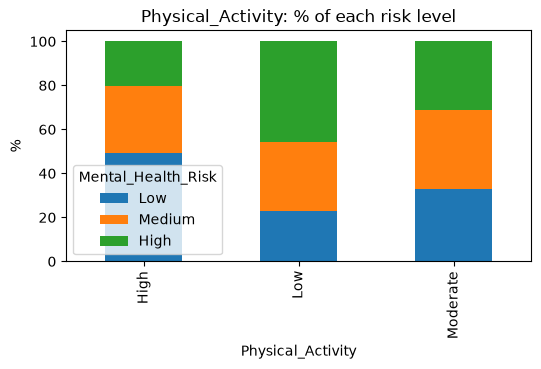

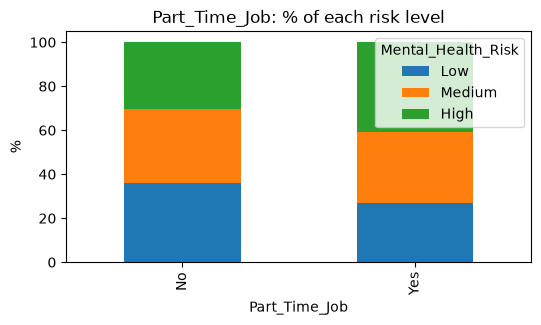

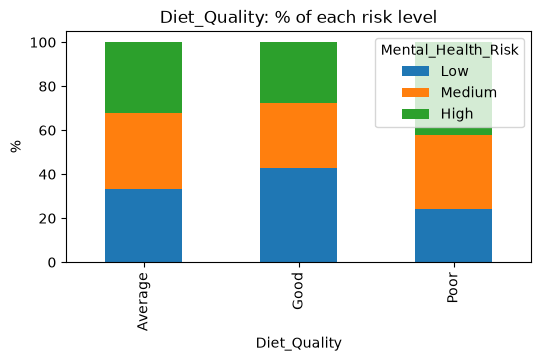

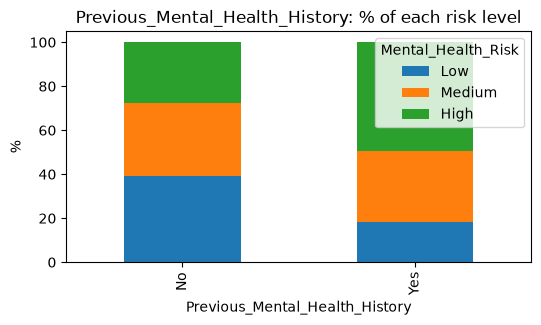

In [ ]:
#featuresvstarget
eda.plot_numeric_vs_target(df, continuous_cols)
eda.plot_categorical_vs_target(df, categorical_cols)

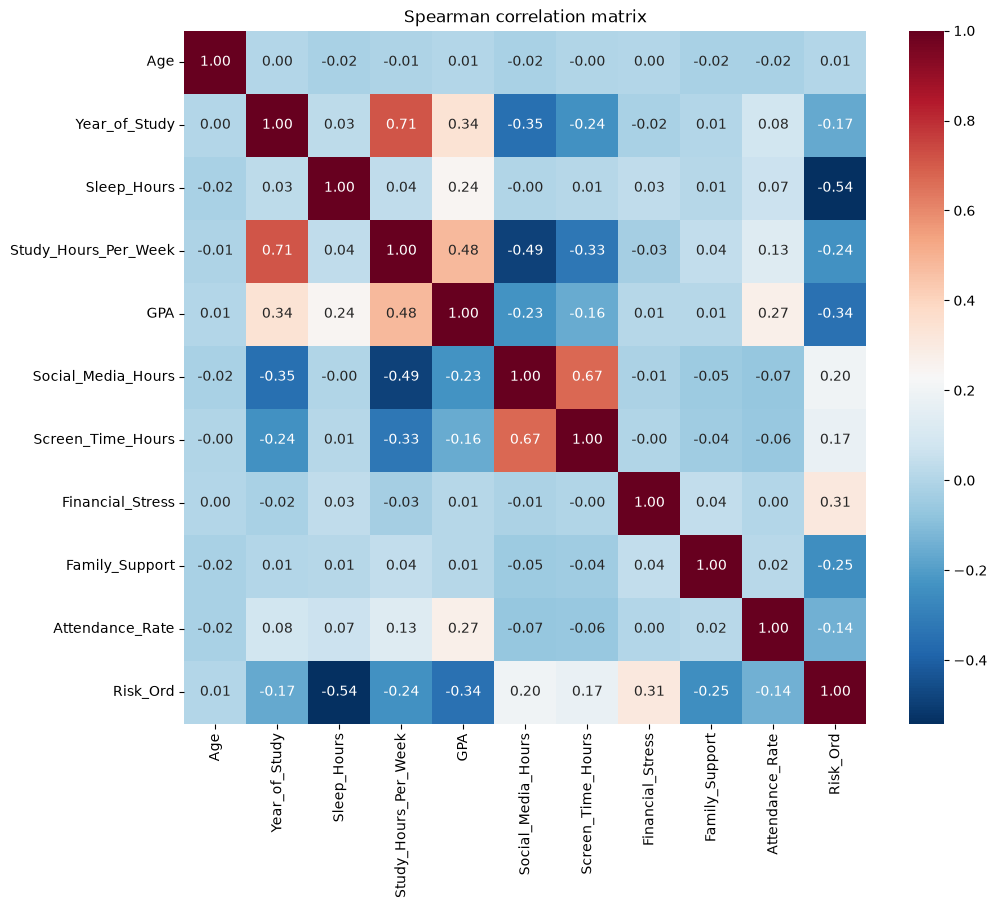

Sleep_Hours             0.541219
GPA                     0.344298
Financial_Stress        0.311370
Family_Support          0.250298
Study_Hours_Per_Week    0.240049
Social_Media_Hours      0.198289
Screen_Time_Hours       0.173464
Year_of_Study           0.165839
Attendance_Rate         0.141808
Age                     0.005131
dtype: float64
Previous_Mental_Health_History    2.942223e-26
Physical_Activity                 2.851453e-23
Diet_Quality                      6.142963e-10
Part_Time_Job                     1.592867e-06
Gender                            2.769132e-01
dtype: float64


In [ ]:
#correlation+ranking
eda.plot_correlation(df, numeric_cols)
print(eda.rank_numeric_features(df, numeric_cols))
print(eda.rank_categorical_features(df, categorical_cols))